# Process tomography for DB-QITE using DME
## 1. Define the DME circuit

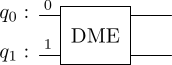

In [3]:
import sys; sys.path.append('..')
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import Gate, Parameter
from qiskit.circuit.library import RZZGate
from qiskit_aer import AerSimulator
from qiskit_experiments.library.tomography import ProcessTomography
from functions.plot_process_matrix import plot_process_matrix

# Define symbolic parameter
t = np.pi*0.14

# Create subcircuit with symbolic parameter
subcircuit = QuantumCircuit(2, name='DME')

# ZZ gate
subcircuit.append(RZZGate(t), [0, 1])

# YY gate
subcircuit.sdg(0)
subcircuit.sdg(1)
subcircuit.h(0)
subcircuit.h(1)
subcircuit.append(RZZGate(t), [0, 1])
subcircuit.h(0)
subcircuit.h(1)
subcircuit.s(0)
subcircuit.s(1)

# XX gate
subcircuit.h(0)
subcircuit.h(1)
subcircuit.append(RZZGate(t), [0, 1])
subcircuit.h(0)
subcircuit.h(1)

# Convert subcircuit to a parameterized gate
dme_gate = subcircuit.to_gate(label="DME")

# Use the gate in another circuit
qc = QuantumCircuit(2)
qc.append(dme_gate, [0, 1])

# Assign value to the parameter
qc.draw(output='latex', style="bw")


## 2. Circuit A: k1, M1

state Choi([[ 9.84744013e-01+0.00000000e+00j,  1.64014288e-02-8.22072717e-04j,
       -8.58409528e-03+5.27305129e-04j, -3.00296685e-03-5.34284645e-03j,
        1.25949282e-02-5.64384505e-04j, -2.12743315e-03-5.87099346e-05j,
        5.29401464e-03-9.80244426e-01j, -8.33865321e-03-2.47701927e-03j,
       -4.55782899e-03-4.21697329e-03j,  2.90537405e-03-9.87534950e-01j,
       -6.20453358e-04+6.68174144e-03j,  8.20041464e-03+1.21864268e-02j,
       -1.69903926e-03-1.31017708e-02j,  3.74509219e-03+5.75454505e-03j,
        1.11557726e-02-6.14533284e-03j,  9.75076628e-01+1.53692866e-02j],
      [ 1.64014288e-02+8.22072717e-04j,  7.68079471e-03+0.00000000e+00j,
        2.34519011e-03+6.46114636e-03j, -2.57842823e-03-1.09023631e-03j,
        1.45593805e-03-2.20595982e-03j, -5.84166070e-03-5.99550110e-03j,
        3.01761278e-03-2.51214317e-02j,  3.37901127e-03-1.84950080e-03j,
       -4.37923228e-03+2.28868535e-04j,  2.02319444e-03-1.83056435e-02j,
        5.46540486e-03-2.27701194e-03j,  3.2

C:\Users\Admin\AppData\Local\Temp\ipykernel_9484\440297760.py:22: DeprecationWarning: Leaving `dataframe` unset or setting it to `False` for `ExperimentData.analysis_results` is deprecated as of qiskit-experiments 0.9.0. Future releases may change the default to `True` and remove the option to set the value to `False`.
  for res in tomo_result.analysis_results():
C:\Users\Admin\AppData\Local\Temp\ipykernel_9484\440297760.py:26: DeprecationWarning: Leaving `dataframe` unset or setting it to `False` for `ExperimentData.analysis_results` is deprecated as of qiskit-experiments 0.9.0. Future releases may change the default to `True` and remove the option to set the value to `False`.
  choi = tomo_result.analysis_results()[0].value


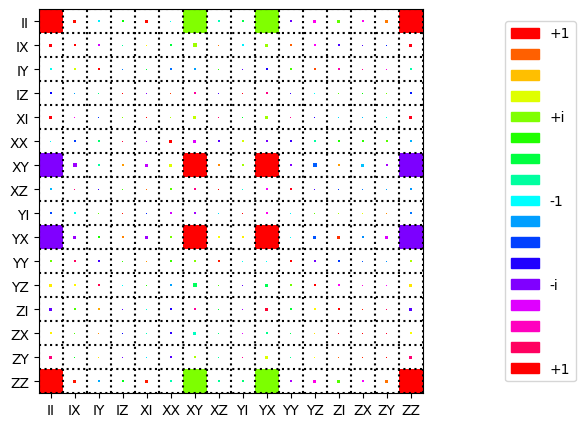

In [48]:
# 1. Create a quantum circuit with two qubits
qc = QuantumCircuit(2)
phi_z = 0.89
# qc.rz(phi=phi_z,qubit=0)
# qc.append(dme_gate, [0, 1])  # DME gate on q_0 and q_1
# qc.rz(phi=-phi_z,qubit=0)
qc.iswap(0,1)
# Draw the circuit
qc.draw(output='latex', style="bw")
# 2. Set up the process tomography experiment
process_tomo = ProcessTomography(qc)

# 3. Run the experiment
simulator = AerSimulator()
tomo_job = process_tomo.run(simulator)
tomo_result = tomo_job.block_for_results()

# 4. Analyze the results
from qiskit.quantum_info import Choi

# List all available analysis results
for res in tomo_result.analysis_results():
    print(res.name, res.value)

# Typically, you can extract the Choi matrix like this:
choi = tomo_result.analysis_results()[0].value

# Assuming 1-qubit process
pauli_labels = ["I", "X", "Y", "Z"]
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
 'XI', 'XX', 'XY', 'XZ',
 'YI', 'YX', 'YY', 'YZ',
 'ZI', 'ZX', 'ZY', 'ZZ']
plot_process_matrix(np.asarray(choi), pauli_labels_2q)

In [64]:
ZZ = tensor(sigmaz(),sigmaz())

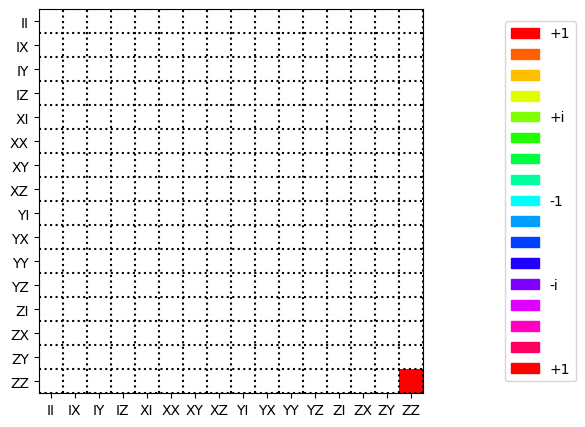

: 

In [ ]:
from qutip.tomography import qpt
from qutip import gates, spre,spost,qeye,sigmax,sigmay,sigmaz,tensor
U_psi = ZZ

U_rho = spre(U_psi) * spost(U_psi.dag())
op_basis = [[qeye(2), sigmax(), sigmay(), sigmaz()]] * 2

import matplotlib.pyplot as plt
chi = qpt(U_rho, op_basis)
# fig = qpt_plot_combined(chi, pauli_labels_2q, r'$i$SWAP')
# plt.show()
plot_process_matrix(np.asarray(chi), pauli_labels_2q)